# Task 53: Manual SHAP-Style Explanations

Enumerate feature coalitions, calculate exact interventional Shapley values for an individual prediction, verify additivity, and summarize attribution variability.

Prediction: 0.7297 background: 0.6825 additivity: 0.7297


,Feature,Case value (standardized),Shapley contribution
1,sex,0.7049,-0.1398
11,ca,-0.7474,0.1375
7,thalach,-0.4397,-0.0483
8,exang,-0.6852,0.0456
9,oldpeak,-0.8844,0.0411
3,trestbps,-0.2017,0.0390
2,cp,0.0159,-0.0389
6,restecg,-1.0403,-0.0373
10,slope,1.0051,0.0202
4,chol,-0.6698,0.0178


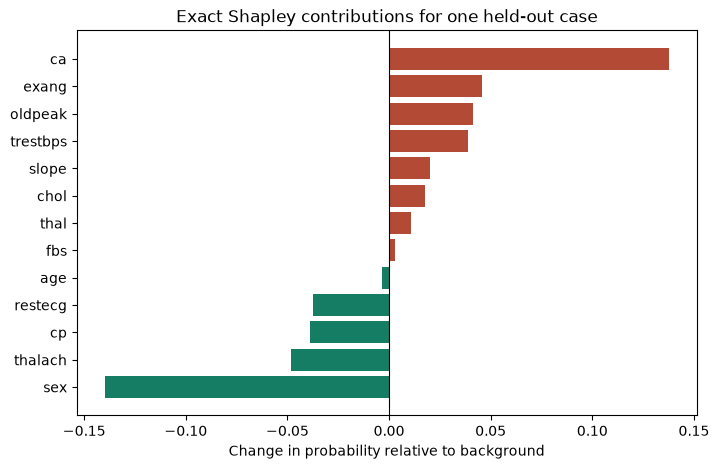

Feature impact variability across cases:


,Feature,Mean |contribution|,Contribution SD across cases
11,ca,0.1074,0.1024
2,cp,0.1044,0.0848
1,sex,0.1024,0.0969
9,oldpeak,0.0731,0.0876
7,thalach,0.0588,0.0677
8,exang,0.0455,0.0452
12,thal,0.0415,0.0491
6,restecg,0.0308,0.0233
10,slope,0.0246,0.0264
3,trestbps,0.0225,0.0265


Exact enumeration needs 2^p coalitions. Interventional background replacement can create unrealistic combinations for correlated features; encoded category values are treated numerically and explanations are not causal.


In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths=[Path('heart.csv'),Path('Task_53_Manual_SHAP_Explanations/heart.csv'),Path('Heart_Disease_Tasks/Task_53_Manual_SHAP_Explanations/heart.csv')]
data=pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features=[c for c in ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal'] if c in data]
X,y=data[features].to_numpy(float),data.target.to_numpy(int)
def split(labels,fraction,seed):
    rng=np.random.default_rng(seed);a=[];b=[]
    for label in np.unique(labels):
        ids=np.flatnonzero(labels==label);rng.shuffle(ids);cut=round(fraction*len(ids));a.extend(ids[:cut]);b.extend(ids[cut:])
    rng.shuffle(a);rng.shuffle(b);return np.array(a),np.array(b)
train,test=split(y,.8,53);Xtr,Xte=X[train],X[test];ytr,yte=y[train],y[test]
mean,scale=Xtr.mean(0),Xtr.std(0);scale[scale==0]=1;Xtr,Xte=(Xtr-mean)/scale,(Xte-mean)/scale
class Logistic:
    def fit(self,x,y):
        self.w=np.zeros(x.shape[1]);self.b=0.
        for _ in range(1200):
            p=1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)));e=p-y;self.w-=.06*(x.T@e/len(y)+.02*self.w);self.b-=.06*e.mean()
        return self
    def proba(self,x):return 1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)))
model=Logistic().fit(Xtr,ytr)
background=Xtr[np.linspace(0,len(Xtr)-1,min(8,len(Xtr)),dtype=int)]

def exact_shap(predict,instance,background):
    p=len(instance)
    if p>16:raise ValueError('Exact Shapley calculation grows exponentially; reduce the feature count.')
    masks=np.arange(1<<p,dtype=np.int64);bits=1<<np.arange(p);included=(masks[:,None]&bits[None,:])!=0
    values=np.zeros(len(masks))
    for start in range(0,len(masks),128):
        stop=min(start+128,len(masks));hybrid=np.where(included[start:stop,None,:],instance[None,None,:],background[None,:,:])
        values[start:stop]=predict(hybrid.reshape(-1,p)).reshape(stop-start,len(background)).mean(axis=1)
    phi=np.zeros(p);denominator=math.factorial(p)
    for j in range(p):
        bit=1<<j;eligible=masks[(masks&bit)==0]
        for mask in eligible:
            size=int(mask).bit_count();weight=math.factorial(size)*math.factorial(p-size-1)/denominator
            phi[j]+=weight*(values[mask|bit]-values[mask])
    return float(values[0]),phi

case_index=0;instance=Xte[case_index]
base,attributions=exact_shap(model.proba,instance,background)
prediction=float(model.proba(instance[None,:])[0])
assert np.isclose(base+attributions.sum(),prediction,atol=1e-8)
print('Prediction:',round(prediction,4),'background:',round(base,4),'additivity:',round(base+attributions.sum(),4))
explanation=pd.DataFrame({'Feature':features,'Case value (standardized)':instance,'Shapley contribution':attributions}).sort_values('Shapley contribution',key=np.abs,ascending=False)
display(explanation.round(4))
plot=explanation.sort_values('Shapley contribution');fig,ax=plt.subplots(figsize=(8,5))
ax.barh(plot['Feature'],plot['Shapley contribution'],color=np.where(plot['Shapley contribution']>=0,'#b34a36','#147d64'));ax.axvline(0,color='black',linewidth=.8)
ax.set_xlabel('Change in probability relative to background');ax.set_title('Exact Shapley contributions for one held-out case');plt.show()

selected=np.linspace(0,len(Xte)-1,min(5,len(Xte)),dtype=int);contributions=[]
for i in selected:contributions.append(exact_shap(model.proba,Xte[i],background)[1])
contributions=np.asarray(contributions)
variability=pd.DataFrame({'Feature':features,'Mean |contribution|':np.mean(np.abs(contributions),axis=0),'Contribution SD across cases':np.std(contributions,axis=0)}).sort_values('Mean |contribution|',ascending=False)
print('Feature impact variability across cases:');display(variability.round(4))
print('Exact enumeration needs 2^p coalitions. Interventional background replacement can create unrealistic combinations for correlated features; encoded category values are treated numerically and explanations are not causal.')